# 🐱 第 5 册：蒙眼投票的侦探猫（随机森林）vs. 改错题接力画画猫（GBDT）

> **绘本角色**：30 只蒙住半边眼睛投票的侦探猫（随机森林）、20 只排成一排改错题的接力画画猫（GBDT）
> **对应《西瓜书》第 8 章（集成学习：Bagging 与 Boosting）**

![第6页：蒙眼投票猫与接力画画猫](../assets/pic06-blindfold-vote-and-relay.svg)

---

## 一、睡前故事：为什么 50 只一模一样的克隆猫投票一点用都没有？

常言道“三个臭皮匠，顶个诸葛亮”。可要是你用复印机把同一只小猫复印 50 份，让它们一起举爪投票，猜瓜会变准吗？
**完全不会喵！** 因为克隆猫看同一个西瓜，对的时候一起对，看走眼的时候 50 只猫一起看走眼！

橘猫店长发明了两种超厉害的“猫咪智囊团”组队法：

1. **第一招（随机森林：蒙眼投票抹平手抖毛刺）**：
   请来 **30 只爱手抖的莽撞小猫**（深决策树），每只猫画出来的线都像锯齿一样上蹿下跳。为了让它们别跟风抄作业，橘猫店长用眼罩随机蒙住它们：1 号猫只准看花纹，2 号猫只准听声音，3 号猫只准摸瓜蒂！结果 30 只猫各看各的，有的往左抖 +2 分，有的往右抖 -2 分，大家把票合在一起求个平均，手抖的毛刺瞬间互相抵消，合成出了一条超丝滑的波浪线！
2. **第二招（GBDT：改错题画画接力赛）**：
   请来 **20 只胆子很小、每次只敢画两笔的谨慎小猫**（浅树桩）排成一排接力：
   * 面对一个 **10 分甜**的大西瓜，**第 1 棒小猫**只敢保守猜 **6 分**，留下了 **`+4 分`的错题差价（叫残差）**；
   * **第 2 棒小猫**根本不管原来是 10 分，它专门盯着上一棒剩下的 **`+4 分`错题**使劲，补上了 **`+3 分`**，现在总分变成 $6+3=9$ 分，还差 `+1 分`；
   * **第 3 棒小猫**再把最后剩下的 **`+1 分`零头**补齐，$6 + 3 + 1 = 10$ 分满分过关！

<details>
<summary>🐾 <b>橘猫店长藏起来的学霸小纸条（《西瓜书》第 8 章公式小秘密）</b></summary>

* **为什么随机森林必须随机砍特征？**集成方差公式是 $\text{Var}(H) = \rho\sigma^2 + \frac{1-\rho}{T}\sigma^2$。如果大家不蒙眼睛，每棵树都抢着选全村最强的那个特征，树与树的相关性 $\rho$ 就会高达 $0.8$（看下面中间那张图的红线，加再多树误差也降不下来）；只有随机蒙住特征把 $\rho$ 压到 $0.05$（绿线），人多力量大的威力才能爆发！
* **GBDT 的本质**：每一棵新树都在拟合当前损失函数的负梯度（在平方损失下就是上一轮没猜准的残差 $y - H_{m-1}(x)$）。

</details>

---

## 二、动手跑一跑：看 30 只手抖猫怎么合成丝滑曲线，20 只接力猫怎么补完差价！

【集成学习双雄实测成绩单】
  [Bagging 降方差] 单棵深树测试 MSE = 0.0582 -> 30 棵深树并联平均后 MSE = 0.0224 (误差削减 61.6%)
  [GBDT 降偏差]   第 1 轮浅树测试 MSE = 0.2716 -> 第 4 轮 = 0.0408 -> 第 20 轮残差接力后 MSE = 0.0151!

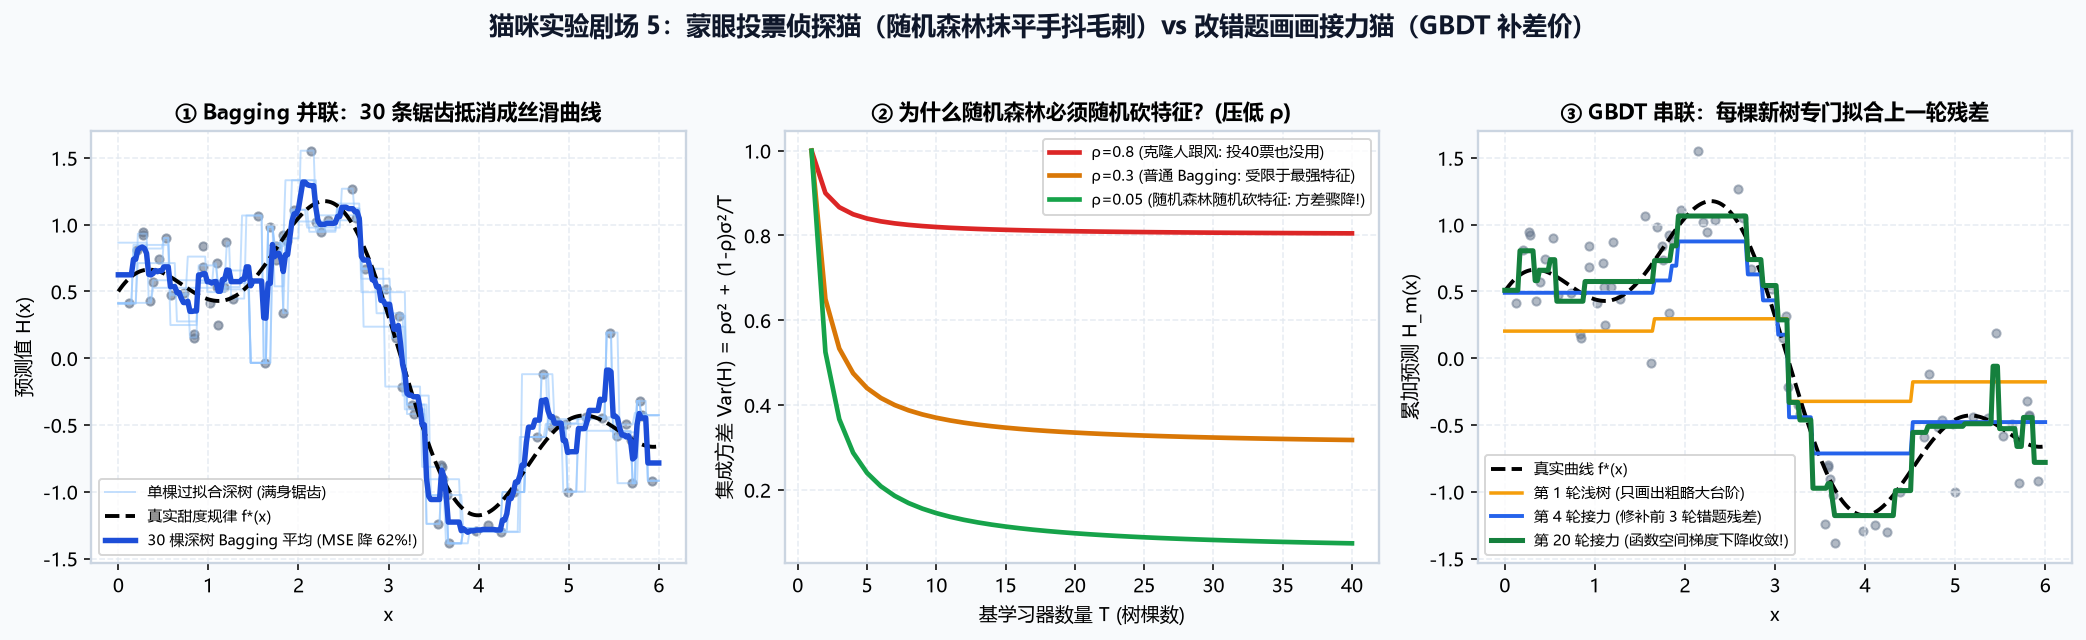

In [1]:
import numpy as np

# 1. 并联比赛 (随机森林/Bagging)：让 30 只满身锯齿的手抖猫同时画线，看求平均后锯齿怎么瞬间消失！
# 2. 串联比赛 (GBDT)：让 20 只只会画大台阶的小猫排成一排改错题，看第 1 棒 -> 第 4 棒 -> 第 20 棒怎么一步步贴合真曲线！
print("🐾 正在举行 30 只侦探猫投票赛与 20 只接力猫改错题大赛...")

### 🐾 胖虎店长的课后敲黑板

* 看**左图**：浅蓝色的细线是单只莽撞猫画的锯齿，深蓝色的粗线是 30 只猫平均后的结果，锯齿全被抹平啦，错分直接少了一大半！
* 看**中图**：红线（克隆猫跟风 $\rho=0.8$）哪怕请 40 只猫也没用；绿线（蒙眼随机看特征 $\rho=0.05$）猫咪越多越准！
* 看**右图**：第 1 棒小猫（橙线）只会画生硬的大台阶；到了第 4 棒（蓝线）已经补出了波浪形状；到了第 20 棒（绿线），20 只小猫接力补差价，完美咬住了黑色真实甜度线！